### Die Mandelbrotmenge

In der Mandelbrotmenge steckt im Kern eine Rekursion. Jeder Zahl $c$ wird eine Folge von Zahlen zugeordnet:
Sie beginnt mit 0, und jedes weitere Folgenglied ist das Quadrat des Vorgängers plus $c$.

<img src='mandel10.png' width='601'>

In [1]:
# rekursive Variante
def mandel(c, k):
    '''
    c: Zahl, k: int
    returns: das Element mit Index k in der Mandelbrot-Folge zur Zahl c
    '''
    if k == 0: return 0
    return mandel(c, k-1)**2 + c

In [2]:
mandel(0.24, 5)

0.3610730012004192

Wollen wir die ganze Folge haben, ist die iterative Variante besser: Die rekursive Funktion müsste für jedes
Folgenglied alle Vorgänger noch einmal berechnen.

In [3]:
def mandelfolge(c, k=10):
    '''
    c: Zahl, k: int
    returns: Liste mit den ersten k Elementen der Mandelbrot-Folge zur Zahl c
    '''
    a = []
    z = 0
    for i in range(k):
        a.append(z)
        z = z**2 + c
    return a

In [4]:
mandelfolge(0.24)

[0,
 0.24,
 0.2976,
 0.32856576,
 0.3479554586443776,
 0.3610730012004192,
 0.3703737121958779,
 0.377176686685755,
 0.3822622529792442,
 0.3861244300527677]

Ein Beispiel von Hand: Für $c = 1$ erhalten wir $0,\ 1,\ 1^2+1 = 2,\ 2^2+1 = 5,\ 5^2+1 = 26, \dots$
Die Folge wächst immer schneller. Für $c = -1$ erhalten wir $0,\ -1,\ (-1)^2-1 = 0,\ 0^2-1 = -1, \dots$
Die Folge springt zwischen 0 und $-1$ hin und her.

Es gilt: Wird ein Folgenglied betragsmäßig größer als 2, dann „explodiert“ die Folge: Die Folgenglieder gehen
betragsmäßig gegen unendlich.

In [5]:
mandelfolge(-1.5)

[0,
 -1.5,
 0.75,
 -0.9375,
 -0.62109375,
 -1.1142425537109375,
 -0.25846353149972856,
 -1.4331966028846888,
 0.5540525025202121,
 -1.1930258244510903]

**Eine Zahl c gehört zur Mandelbrotmenge, wenn die Elemente der zu c gehörenden Folge beschränkt bleiben, also
betragsmäßig kleiner oder gleich 2 bleiben.**

In [6]:
print(mandelfolge(-2))
print(mandelfolge(-1))
print(mandelfolge(0))
print(mandelfolge(0.25))
print(mandelfolge(0.5))

[0, -2, 2, 2, 2, 2, 2, 2, 2, 2]
[0, -1, 0, -1, 0, -1, 0, -1, 0, -1]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0.25, 0.3125, 0.34765625, 0.3708648681640625, 0.38754075043834746, 0.4001878332503175, 0.4101503018815839, 0.4182232701335544, 0.42491070368120404]
[0, 0.5, 0.75, 1.0625, 1.62890625, 3.1533355712890625, 10.443525225156918, 109.56721912848886, 12005.475507550294, 144131442.66239]


Bei manchen Zahlen dauert es länger, bis wir feststellen, dass sie nicht zur Mandelbrotmenge gehören.

In [7]:
mandelfolge(0.26, 35)

[0,
 0.26,
 0.3276,
 0.36732176,
 0.3949252753694976,
 0.4159659731256735,
 0.43302769079838854,
 0.4475129809981848,
 0.4602678681618817,
 0.4718465104622833,
 0.48263912943543363,
 0.4929405292621933,
 0.5029903653892912,
 0.5129993076744527,
 0.5231682896744678,
 0.5337050593209078,
 0.5448410903447338,
 0.5568518137280385,
 0.5700839424522061,
 0.5849957014418502,
 0.6022199707054423,
 0.6226688931164638,
 0.6477165504548822,
 0.679536729733172,
 0.721770167056454,
 0.7809521740527016,
 0.8698862981576411,
 1.0167021717224043,
 1.2936833059850532,
 1.9336164961844169,
 3.9988727543165012,
 16.25098330521484,
 264.3544583863715,
 69883.53966875182,
 4883709116.89401]

Uns interessiert, ab welchem Index die Folge betragsmäßig größer als 2 wird, falls das überhaupt passiert.
Diesen Index nennen wir die **Mandelzahl** von $c$. Wir prüfen dabei nur die ersten `kmax` Folgenglieder.
Ist keines davon betragsmäßig größer als 2, gibt die Funktion $-1$ zurück.

In [8]:
def mandelzahl(c, kmax):
    '''
    c: Zahl, kmax: int, Anzahl der Folgenglieder, die geprüft werden
    returns: Index des ersten Folgenglieds, das betragsmäßig größer als 2 ist
             -1 falls alle kmax Folgenglieder betragsmäßig <= 2
    '''
    z = 0
    for i in range(kmax):
        if abs(z) > 2: return i
        z = z**2 + c
    return -1

In [9]:
mandelzahl(-2.0001, 1000)

1

Bei 0.25 ist eine Grenze:

In [10]:
c = 0.24
diff = 0.001
for i in range(20):
    print(round(c, 3), mandelzahl(c, 1000))
    c += diff

0.24 -1
0.241 -1
0.242 -1
0.243 -1
0.244 -1
0.245 -1
0.246 -1
0.247 -1
0.248 -1
0.249 -1
0.25 -1
0.251 97
0.252 68
0.253 55
0.254 48
0.255 43
0.256 39
0.257 36
0.258 33
0.259 31


Bei $-2$ ist eine weitere Grenze.

**Die reellen Zahlen im Intervall $[-2;\ 0.25]$ gehören zur Mandelbrotmenge.**

## Komplexe Zahlen

Eine reelle Zahl stellen wir uns vor als Punkt auf einer Geraden, der Zahlengeraden. Eine komplexe Zahl stellen wir
uns vor als Punkt in einer Ebene, der Gaußschen Zahlenebene. Statt der Koordinaten $(a|b)$ schreiben wir $a + bi$.
Die Zahl $a$ nennen wir den Realteil, $b$ den Imaginärteil der komplexen Zahl.

<img src="mandel1.png" width="500">

Der Betrag einer komplexen Zahl ist ihr Abstand zum Nullpunkt. Nach dem Satz des Pythagoras gilt
$|a + bi| = \sqrt{a^2 + b^2}$, z.B. $|3 + 2i| = \sqrt{9 + 4} = \sqrt{13} \approx 3.61$.

<img src="mandel1a.png" width="500">

In [11]:
# In Python wird der Imaginärteil durch ein nachgestelltes j gekennzeichnet
z = 3 + 2j
abs(z)

3.605551275463989

Zwei komplexe Zahlen werden addiert, indem die Realteile und die Imaginärteile addiert werden. Dies entspricht der
normalen Vektoraddition.

<img src="mandel2.png" width="501">

In [12]:
z1 = 3 + 2j
z2 = -2 + 1j
z1 + z2

(1+3j)

Zwei komplexe Zahlen werden multipliziert, indem die Beträge multipliziert und die Winkel addiert werden.
Insbesondere gilt dann: $i^2 = -1$, denn $i$ hat den Betrag 1 und den Winkel 90°.

<img src="mandel3.png" width="651">

Wie im Bild können wir auch einfach ausmultiplizieren und dann $i^2 = -1$ einsetzen:

$(a + bi)(c + di) = ac + adi + bci + bdi^2 = (ac - bd) + (ad + bc)i$

Für das Quadrat einer komplexen Zahl gilt damit: $(a + bi)^2 = a^2 - b^2 + 2abi$

In [13]:
1j ** 2

(-1+0j)

In [14]:
z1 = 3 + 2j
z2 = -2 + 1j
z1 * z2

(-8-1j)

#### Übung:

$z_1 = 3 - i, z_2 = 3 + 2i$. Berechne

- $z_1 + z_2$
- $z_1 \cdot z_2$
- $z_1^2 + z_2$

In [15]:
z1 = 3 - 1j
z2 = 3 + 2j
z1 + z2, z1 * z2, z1**2 + z2

((6+1j), (11+3j), (11-4j))

### Anwendung der Mandel-Funktionen auf komplexe Zahlen

Die Funktionen `mandel`, `mandelfolge` und `mandelzahl` funktionieren genauso mit komplexen Zahlen.

Ein Beispiel von Hand: Für $c = i$ erhalten wir

- $z_0 = 0$
- $z_1 = 0^2 + i = i$
- $z_2 = i^2 + i = -1 + i$
- $z_3 = (-1 + i)^2 + i = (1 - 1 - 2i) + i = -i$
- $z_4 = (-i)^2 + i = -1 + i$

Ab $z_2$ wechseln sich $-1 + i$ und $-i$ ab. Die Folge bleibt beschränkt, $i$ gehört also zur Mandelbrotmenge.

In [16]:
mandelfolge(1j)

[0, 1j, (-1+1j), -1j, (-1+1j), -1j, (-1+1j), -1j, (-1+1j), -1j]

In [17]:
mandelfolge(0.24 + 0.1j)

[0,
 (0.24+0.1j),
 (0.28759999999999997+0.14800000000000002j),
 (0.30080976+0.1851296j),
 (0.2962135429150976+0.211377581089792j),
 (0.28306198121894277+0.22522580437486125j),
 (0.26939742225528984+0.22750572481595652j),
 (0.26081611629376117+0.22257891162748003j),
 (0.25848367461728716+0.21610433459914324j),
 (0.2601127266111171+0.2117188850158206j)]

Die Mandelbrotfolge entspricht einem Herumspringen auf der Gaußschen Zahlenebene: Beim Quadrieren ändern sich Betrag
und Winkel, dann wird noch $c$ addiert.

[Visualisierung Mandel-Iteration](http://www.stefanbion.de/fraktal-generator/mandeliteration.htm)

Kleine Veränderungen der Zahl führen zu ganz unterschiedlichen Mandelzahlen.

In [18]:
c = 0.251 + 0.5704j
diff = 0.00001j
for i in range(20):
    print(mandelzahl(c, 2000))
    c += diff

-1
-1
-1
-1
-1
1434
608
802
634
378
429
1204
292
282
280
313
319
249
250
274


#### Visualisierung der Mandelbrotmenge

**Die Punkte in der Ebene, die zu komplexen Zahlen der Mandelbrotmenge gehören, färben wir schwarz, die anderen weiß.**

Dazu wählen wir einen Ausschnitt der Gaußschen Zahlenebene und ordnen jedem Pixel eines Bildes eine Zahl aus diesem
Ausschnitt zu.

<img src = 'ebenen.png'>

Mit dem Modul `PIL` (Paket `pillow`) erzeugen wir ein Bild und färben einzelne Pixel. Das Pixel (0, 0) liegt oben links.

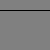

In [19]:
# !pip install pillow
from PIL import Image
img = Image.new('RGB', (50, 50), 'grey')
pixels = img.load()
for x in range(50):
    pixels[x, 10] = 0     # Spalte, Zeile; 0 = schwarz
display(img)

`np.linspace(a, b, n)` aus dem Modul `numpy` liefert `n` Zahlen mit gleichem Abstand von `a` bis `b`.
Mit `enumerate` bekommen wir zu jeder Zahl auch ihren Index.

In [20]:
import numpy as np
for x in np.linspace(0, 10, 5):                  # 5 Zahlen mit gleichem Abstand
    print(x)

0.0
2.5
5.0
7.5
10.0


In [21]:
for ix, x in enumerate(np.linspace(0, 10, 5)):
    print(ix, x)

0 0.0
1 2.5
2 5.0
3 7.5
4 10.0


Welche Zahl gehört zu einem Pixel? Zwischen 600 Zahlen liegen 599 Abstände. Im Ausschnitt von $-2.15$ bis $0.85$
(Breite 3) ist der Abstand benachbarter Zahlen also $3 / 599 \approx 0.005$. Für die Höhe 2.25 und 450 Zahlen ist
er $2.25 / 449 \approx 0.005$. Zum Pixel (100, 50) gehört deshalb die Zahl

$-2.15 + 100 \cdot \frac{3}{599} + \left(1.125 - 50 \cdot \frac{2.25}{449}\right)i \approx -1.65 + 0.874i$

Die y-Werte werden von oben nach unten kleiner, weil die Pixelzeilen nach unten gezählt werden.

In [22]:
print(np.linspace(-2.15, 0.85, 600)[100])
print(np.linspace(1.125, -1.125, 450)[50])

-1.6491652754590984
0.8744432071269488


In [23]:
x0, y0 = -2.15, 1.125            # oben links
x1, y1 = 0.85, -1.125            # unten rechts

# x0, y0 = -1.79, 0.02           # oben links
# x1, y1 = -1.73, -0.02          # unten rechts

# x0, y0 = -1.78668, 0.0005      # oben links
# x1, y1 = -1.78539, -0.0005     # unten rechts

In [24]:
hoehe = y0 - y1
breite = x1 - x0
print(hoehe, breite, hoehe/breite)

2.25 3.0 0.75


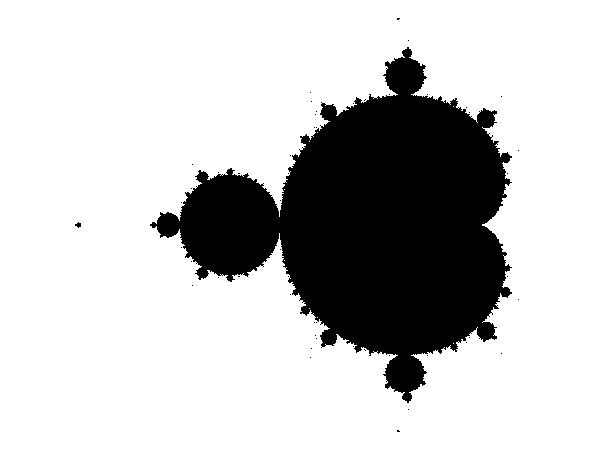

In [25]:
N = 200                            # Anzahl der geprüften Folgenglieder
Nx = 600                           # Anzahl Punkte in x-Richtung
Ny = int(Nx * hoehe/breite)        # Anzahl Punkte in y-Richtung
img = Image.new('RGB', (Nx, Ny), 'white')
pixels = img.load()
for xi, x in enumerate(np.linspace(x0, x1, Nx)):
    for yi, y in enumerate(np.linspace(y0, y1, Ny)):
        c = x + 1j*y
        if mandelzahl(c, N) < 0:
            pixels[xi, yi] = 0
display(img)

Mit den auskommentierten Ausschnitten oben kann man in die Mandelbrotmenge hineinzoomen. Dann muss man `N` erhöhen,
damit die Ränder fein genug werden. In winzigen Ausschnitten tauchen immer wieder Figuren auf, die der ganzen
Mandelbrotmenge ähnlich sehen. Solche selbstähnlichen Bilder heißen **Fraktale**.

Wir färben die nicht-schwarzen Punkte mit Farben ein, abhängig davon, bei welcher Iteration der Punkt als nicht zur
Mandelbrotmenge gehörig entdeckt wurde, also abhängig von der Mandelzahl. Die Farben stehen als RGB-Tupel in einer
Liste. Mit dem Modulo-Operator `%` bleibt der Index immer gültig.

Beispiel: Bei 5 Farben bekommt ein Punkt mit der Mandelzahl 9 die Farbe mit dem Index $9 \% 5 = 4$.

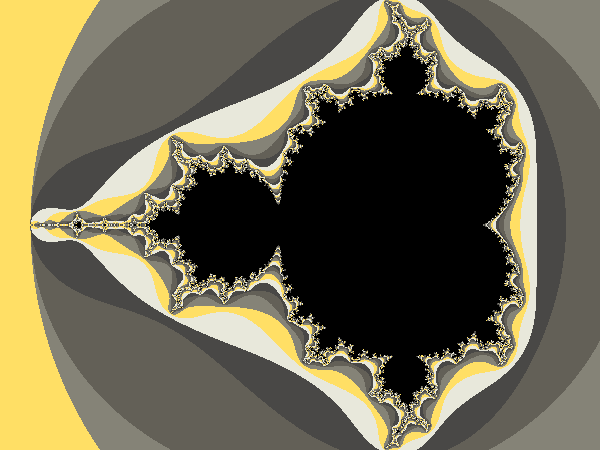

In [26]:
farben = [(232, 232, 219), (255, 223, 101), (133, 131, 119), (99, 96, 87), (73, 72, 70)]
N = 30
img = Image.new('RGB', (Nx, Ny), 'white')
pixels = img.load()
for xi, x in enumerate(np.linspace(x0, x1, Nx)):
    for yi, y in enumerate(np.linspace(y0, y1, Ny)):
        c = x + 1j*y
        mz = mandelzahl(c, N)
        if mz < 0:
            pixels[xi, yi] = 0
        else:
            pixels[xi, yi] = farben[mz % len(farben)]
display(img)

#### Links

* [Mandelbrot-Generator](http://www.stefanbion.de/fraktal-generator/mandelbrot.htm)

* [Visualisierung Mandel-Iteration](http://www.stefanbion.de/fraktal-generator/mandeliteration.htm)

* [Xaos](https://xaos-project.github.io/) fast interactive fractal zoomer

---

In den Numberphile-Videos wird die Mandelbrot-Folge wie folgt definiert:

Für jede Zahl c definieren wir eine Funktion $f_c(z) = z^2 + c$ und betrachten das Verhalten von 0 bei Iteration ("the behaviour of 0 under iteration"). D.h. wir beobachten, was passiert, wenn 
man die 0 in diese Funktion einsetzt und dann das Resultat wieder in die Funktion einsetzt, dann das Resultat wieder in die Funktion einsetzt usw. Dies führt zur Folge $$c , c^2 + c, (c^2 + c)^2 + c, ...$$  

"A number c is in the mandelbrot set if the function $f_c$ does not blow up under iteration of 0"

* [Numberphile: The Mandelbrot-Set](https://www.youtube.com/watch?v=NGMRB4O922I&list=PLt5AfwLFPxWJ8GCgpFo5_OSyfl7j0nOiu&index=1)

* [Numberphile: The Filled Julia-Set](https://www.youtube.com/watch?v=oCkQ7WK7vuY&list=PLt5AfwLFPxWJ8GCgpFo5_OSyfl7j0nOiu&index=4)

* [Numberphile: The Mandelbrot-Set and Pi](https://www.youtube.com/watch?v=d0vY0CKYhPY)

* [Numberphile: The Mandelbrot-Set and the Fibonacci-Numbers](https://www.youtube.com/watch?v=4LQvjSf6SSw&index=6&list=PLt5AfwLFPxWJ8GCgpFo5_OSyfl7j0nOiu&t=0s)


----

* [Mandelbrot zoom](https://www.youtube.com/watch?v=yVBrgxzS7JE)

* [Mandelbox trip](https://www.youtube.com/watch?v=bO9ugnn8DbE)